# COE prices vs rent: is there a strong relationship?

The COE features (`coe_features_monthly.csv`, built in `02_coe_price_features.ipynb`) are the quota premium, the quota and the bids received for each of the
four categories A, B, C and E (`PREVAILING_QUOTA_PREMIUM` is excluded: it depends on the age of the licence). The premium enters as a log, like rent.

Three views of the same question:

1. **House level.** Every train + validation flat (2021-01 to 2025-03) is joined to the 12 COE features of its approval month. Each feature is correlated
   with the flat's log rent, and with the log rent left over after the static features (the flat's location, size and type, with no time information).
2. **Monthly level.** The COE features are correlated with the monthly rent trend `alpha_m` (a Ridge of log rent on one dummy per month plus all the static
   features, as in the training pipeline), over the full history and over the later windows the models are trained on.
3. **Monthly changes and lags.** Two trending series correlate in levels even when unrelated, so the same comparison is made on **month-on-month
   changes**, and with the COE feature leading rent by 0 to 6 months.

Nothing is fitted or selected here with the test period; it only reads the relationship.

In [1]:
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

SHARED_DIR = '/Users/keltonn/Desktop/Projects/housing_price_regressor/03b_training_pipeline_model'
sys.path.insert(0, SHARED_DIR)
import pipeline_utils as pu
import plotting

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 100)
CATEGORIES = ['a', 'b', 'c', 'e']
WINDOWS = {'full history (2021-01..2025-03)': 0, '2023 onward': 24, 'after May 2023': 29}     # first month of each window (month 0 = 2021-01)

## 1. Data

In [2]:
coe = pd.read_csv(f'{pu.DATA}/temporal_features/coe_features_monthly.csv')
coe.index = (coe['RENT_APPROVAL_YEAR'] - 2021) * 12 + coe['RENT_APPROVAL_MONTH'] - 1
coe = coe.drop(columns=['RENT_APPROVAL_YEAR', 'RENT_APPROVAL_MONTH'])
coe = coe.rename(columns={c: c.replace('_quota_premium', '_log_quota_premium') for c in coe if c.endswith('_quota_premium')})
for c in [c for c in coe if c.endswith('log_quota_premium')]:
    coe[c] = np.log(coe[c])
coe = coe[[f'coe_{k}_{f}' for k in CATEGORIES for f in ('log_quota_premium', 'quota', 'bids_received')]]
print('COE features', coe.shape, '| complete up to month', int(coe.dropna().index.max()), '(test period ends at month', pu.TEST_LAST, ')')

frames, numeric, onehot = pu.load_static()
tv = pd.concat([frames['train'], frames['validation']], ignore_index=True)
X_tv, y_tv, m_tv = pu.design(tv, numeric, onehot), pu.log_rent(tv), tv['month'].to_numpy()
months = np.arange(0, pu.VALIDATION_LAST + 1)
alpha_m = pu.decompose_trend(X_tv, y_tv, m_tv, months)       # monthly level of the average flat, static differences removed
print(f'train + validation {X_tv.shape}; alpha_m over months {months[0]}..{months[-1]}: {alpha_m.iloc[0]:.3f} -> {alpha_m.iloc[-1]:.3f}')

COE features (68, 12) | complete up to month 66 (test period ends at month 66 )


train + validation (149359, 237); alpha_m over months 0..50: 7.608 -> 8.036


## 2. House level: every flat joined to the COE features of its month

Each flat gets the 12 COE values of its approval month (the join is on year and month). `log rent` is the raw target; `static-adjusted log rent` is log
rent minus what the static features predict (a Ridge on the static features alone, no time information), so what remains is mostly the month it was rented in.
Within a month every flat has the same COE values, so this is a correlation of rent with the month's COE level across 150,000 flats.

In [3]:
joined = coe.loc[m_tv].reset_index(drop=True)                       # one row per flat, the COE features of its month
static_fit = Ridge(alpha=1.0).fit(X_tv, y_tv)
adjusted = y_tv - static_fit.predict(X_tv)
house = pd.DataFrame({'log rent': joined.corrwith(pd.Series(y_tv)), 'static-adjusted log rent': joined.corrwith(pd.Series(adjusted))})
print('static features alone explain', round(1 - adjusted.var() / y_tv.var(), 3), 'of the variance of log rent')
house.round(3)

static features alone explain 0.228 of the variance of log rent


,log rent,static-adjusted log rent
coe_a_log_quota_premium,0.525,0.600
coe_a_quota,0.125,0.142
coe_a_bids_received,0.163,0.186
coe_b_log_quota_premium,0.477,0.546
coe_b_quota,-0.276,-0.316
coe_b_bids_received,-0.171,-0.197
coe_c_log_quota_premium,0.520,0.593
coe_c_quota,0.001,0.000
coe_c_bids_received,-0.070,-0.081
coe_e_log_quota_premium,0.469,0.537


## 3. Monthly level: COE vs the rent trend `alpha_m`

Pearson correlation between each COE feature and `alpha_m` over the months of each window. Months are the observations (51, 27 and 22), not flats.

In [4]:
rows = {}
for name, start in WINDOWS.items():
    idx = months[months >= start]
    rows[name] = coe.loc[idx].corrwith(alpha_m.loc[idx])
level = pd.DataFrame(rows)
level.round(2)

,full history (2021-01..2025-03),2023 onward,after May 2023
coe_a_log_quota_premium,0.94,0.21,0.13
coe_a_quota,0.24,0.87,0.75
coe_a_bids_received,0.30,0.73,0.50
coe_b_log_quota_premium,0.85,-0.14,-0.34
coe_b_quota,-0.47,0.83,0.71
coe_b_bids_received,-0.29,0.71,0.43
coe_c_log_quota_premium,0.93,-0.66,-0.62
coe_c_quota,0.02,0.86,0.77
coe_c_bids_received,-0.10,0.78,0.64
coe_e_log_quota_premium,0.84,-0.19,-0.38


## 4. Month-on-month changes, and COE leading rent

Correlation of the change in `alpha_m` with the change in each COE feature, where the COE change is taken `lag` months **before** the rent change
(lag 0 = same month). The full history is used, then only the months after May 2023. With 50 and 21 changes, a correlation has to be about 0.28 and 0.43
in absolute value to be distinguishable from noise at the usual 5% level (and that is optimistic: monthly changes are autocorrelated).

In [5]:
d_alpha, d_coe = alpha_m.diff(), coe.diff()
tables = {}
for name, start in [('full history', 1), ('after May 2023', 30)]:
    t = {}
    for lag in range(7):
        idx = [m for m in months if m >= start and (m - lag) >= 1]
        t[f'lag {lag}'] = pd.Series({c: d_alpha.loc[idx].corr(d_coe[c].shift(lag).loc[idx]) for c in coe})
    tables[name] = pd.DataFrame(t)
    display(tables[name].round(2).rename_axis(f'corr(change in alpha_m, change in COE feature lagged k months), {name}'))

,lag 0,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6
"corr(change in alpha_m, change in COE feature lagged k months), full history",,,,,,,
coe_a_log_quota_premium,0.25,0.15,0.17,0.35,0.18,0.14,-0.04
coe_a_quota,-0.15,-0.19,-0.07,-0.24,-0.19,0.06,-0.32
coe_a_bids_received,-0.11,-0.12,-0.06,-0.24,-0.06,0.15,-0.23
coe_b_log_quota_premium,0.05,0.17,0.10,0.24,0.07,0.17,-0.00
coe_b_quota,-0.19,-0.16,-0.20,-0.20,-0.08,-0.09,-0.33
coe_b_bids_received,-0.19,-0.07,0.01,-0.16,-0.05,-0.03,-0.10
coe_c_log_quota_premium,0.21,0.29,0.22,0.18,0.21,0.27,-0.02
coe_c_quota,-0.08,-0.02,-0.05,-0.17,-0.02,-0.10,-0.07
coe_c_bids_received,-0.06,-0.01,-0.01,-0.11,-0.07,-0.08,0.06


,lag 0,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6
"corr(change in alpha_m, change in COE feature lagged k months), after May 2023",,,,,,,
coe_a_log_quota_premium,0.13,-0.10,0.07,0.29,-0.10,0.01,-0.42
coe_a_quota,-0.10,0.08,-0.04,-0.27,0.08,0.10,-0.20
coe_a_bids_received,-0.07,-0.01,0.07,-0.28,0.15,0.26,-0.02
coe_b_log_quota_premium,-0.10,-0.01,0.15,0.05,-0.17,0.08,-0.29
coe_b_quota,-0.03,0.14,-0.23,-0.13,0.32,-0.09,-0.15
coe_b_bids_received,-0.40,0.01,0.20,-0.23,0.06,0.08,0.05
coe_c_log_quota_premium,0.07,0.20,0.13,-0.58,0.25,0.43,-0.41
coe_c_quota,-0.23,0.06,-0.05,-0.20,0.19,-0.27,0.06
coe_c_bids_received,-0.12,-0.05,-0.08,0.17,-0.35,-0.08,0.35


In [6]:
# a monthly series of 50 changes: the size of correlation that noise alone produces
rng = np.random.default_rng(0)
for n in (50, 21):
    r = [np.corrcoef(rng.normal(size=n), rng.normal(size=n))[0, 1] for _ in range(20000)]
    print(f'n = {n} monthly changes: 95% of unrelated pairs have |corr| below {np.quantile(np.abs(r), 0.95):.2f}')

n = 50 monthly changes: 95% of unrelated pairs have |corr| below 0.28


n = 21 monthly changes: 95% of unrelated pairs have |corr| below 0.43


## 5. Picture: standardised log premium of each category against the rent trend

Levels, each series standardised over 2021-01..2025-03, so the shapes compare. The premium of a category rising with the rent trend would show up as lines
that move together.

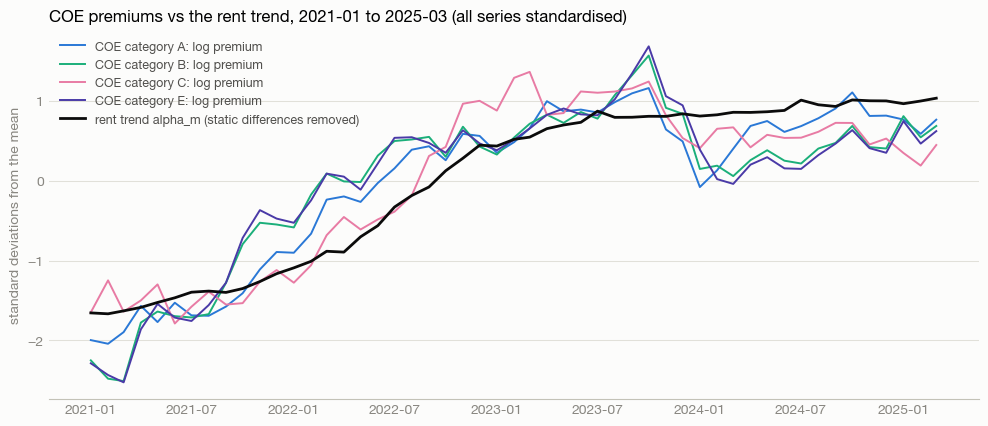

In [7]:
plotting._style()
fig, ax = plt.subplots(figsize=(12, 4.8), facecolor=plotting.SURFACE)
x = pd.period_range('2021-01', periods=len(months), freq='M').to_timestamp()
z = lambda s: (s - s.mean()) / s.std()
colours = {'a': plotting.HUE['blue'], 'b': plotting.HUE['aqua'], 'c': plotting.HUE['magenta'], 'e': plotting.HUE['violet']}
for k in CATEGORIES:
    ax.plot(x, z(coe.loc[months, f'coe_{k}_log_quota_premium']), color=colours[k], lw=1.4, label=f'COE category {k.upper()}: log premium')
ax.plot(x, z(alpha_m), color=plotting.INK, lw=2.0, label='rent trend alpha_m (static differences removed)')
ax.set_facecolor(plotting.SURFACE); ax.grid(axis='y', color=plotting.GRID, lw=0.75); ax.set_axisbelow(True)
for side in ('top', 'right', 'left'):
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color(plotting.AXIS); ax.tick_params(colors=plotting.MUTED, length=0)
ax.set_ylabel('standard deviations from the mean', color=plotting.MUTED)
ax.set_title('COE premiums vs the rent trend, 2021-01 to 2025-03 (all series standardised)', loc='left', fontsize=12, fontweight='semibold')
ax.legend(frameon=False, fontsize=9, labelcolor=plotting.INK2, loc='upper left')
plt.show()

## 6. Out-of-sample check: can a category's COE features forecast the trend?

For each category (its three features together) and for all four categories together, a Ridge (penalty by forward-chaining cross-validation) is fit to
`alpha_m` on the training months (to 2024-09) and used to forecast the six validation months (2024-10 to 2025-03). The benchmark is carrying the last
training level forward. This is a small check (six months, and `alpha_m` is nearly flat there), so it can rule a feature out more than it can rule one in.

In [8]:
def forecast_rmse(columns, start):
    fit = np.arange(max(start, 1), pu.TRAIN_LAST + 1)
    valid = np.arange(pu.VALIDATION_FIRST, pu.VALIDATION_LAST + 1)
    scaler = StandardScaler().fit(coe.loc[fit, columns])
    model = RidgeCV(alphas=np.logspace(-2, 4, 25), cv=TimeSeriesSplit(4), scoring='neg_mean_squared_error')
    model.fit(scaler.transform(coe.loc[fit, columns]), alpha_m.loc[fit])
    forecast = model.predict(scaler.transform(coe.loc[valid, columns]))
    return float(np.sqrt(np.mean((alpha_m.loc[valid].values - forecast) ** 2)))


carry = {name: float(np.sqrt(np.mean((alpha_m.loc[45:50].values - alpha_m.loc[pu.TRAIN_LAST]) ** 2))) for name in WINDOWS}
sets = {f'category {k.upper()}': [c for c in coe if c.startswith(f'coe_{k}_')] for k in CATEGORIES} | {'all four categories': list(coe)}
check = pd.DataFrame({name: {label: forecast_rmse(cols, start) for label, cols in sets.items()} | {'carry last level forward': carry[name]}
                      for name, start in WINDOWS.items()})
check.round(4).rename_axis('validation RMSE of the forecast of alpha_m (log rent units)')

,full history (2021-01..2025-03),2023 onward,after May 2023
validation RMSE of the forecast of alpha_m (log rent units),,,
category A,0.0370,0.0034,0.0125
category B,0.0326,0.0079,0.0178
category C,0.0527,0.0113,0.0148
category E,0.1053,0.0182,0.0143
all four categories,0.0253,0.0086,0.0129
carry last level forward,0.0118,0.0118,0.0118
